# Philadelphia Regression Analysis

This notebook loads the Philadelphia restaurant feature dataset and runs the business, review, check-in, and photo regressions.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"
target_city = "Philadelphia"
philadelphia_path = processed_dir / "restaurant_review_checkin_photo_features_philadelphia.csv"
fallback_path = processed_dir / "restaurant_review_checkin_photo_features.csv"

data_path = philadelphia_path if philadelphia_path.exists() else fallback_path
restaurants = pd.read_csv(data_path).rename(columns={"average_sentiment": "avg_sentiment"})

if "city" not in restaurants.columns:
    raise KeyError("Expected a 'city' column in the restaurant feature dataset.")

restaurants = restaurants.loc[
    restaurants["city"].fillna("").str.casefold() == target_city.casefold()
].copy()

print(f"Using {len(restaurants):,} {target_city} restaurants from {data_path.name}.")
restaurants.head()


Using 5,854 Philadelphia restaurants from restaurant_review_checkin_photo_features_philadelphia.csv.


,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,...,photo_count,photo_file_count,photo_file_coverage,avg_image_brightness,avg_image_saturation,food_photo_share,inside_photo_share,outside_photo_share,drink_photo_share,menu_photo_share
0,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,935 Race St,Philadelphia,PA,19107.0,39.955505,-75.155564,4.0,80,...,7.0,7.0,1.0,0.658424,0.334994,0.857143,0.000000,0.142857,0.000000,0.0
1,MUTTqe8uqyMdBl186RmNeA,Tuna Bar,205 Race St,Philadelphia,PA,19106.0,39.953949,-75.143226,4.0,245,...,27.0,27.0,1.0,0.509289,0.351132,0.777778,0.148148,0.000000,0.074074,0.0
2,ROeacJQwBeh05Rqg7F6TCg,BAP,1224 South St,Philadelphia,PA,19147.0,39.943223,-75.162568,4.5,205,...,3.0,3.0,1.0,0.497876,0.460593,0.333333,0.666667,0.000000,0.000000,0.0
3,QdN72BWoyFypdGJhhI5r7g,Bar One,767 S 9th St,Philadelphia,PA,19147.0,39.939825,-75.157447,4.0,65,...,1.0,1.0,1.0,0.575579,0.277453,0.000000,1.000000,0.000000,0.000000,0.0
4,Mjboz24M9NlBeiOJKLEd_Q,DeSandro on Main,4105 Main St,Philadelphia,PA,19127.0,40.022466,-75.218314,3.0,41,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0


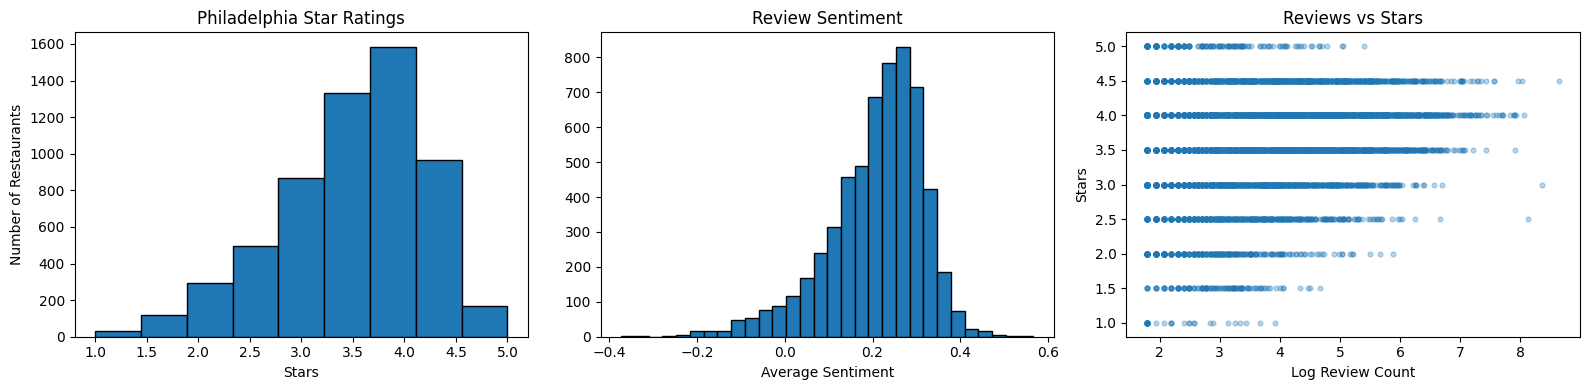

In [2]:
# Basic distributions used to understand the regression inputs.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(restaurants["stars"].dropna(), bins=9, edgecolor="black")
axes[0].set_xlabel("Stars")
axes[0].set_ylabel("Number of Restaurants")
axes[0].set_title("Philadelphia Star Ratings")

axes[1].hist(restaurants["avg_sentiment"].dropna(), bins=30, edgecolor="black")
axes[1].set_xlabel("Average Sentiment")
axes[1].set_title("Review Sentiment")

axes[2].scatter(restaurants["log_review_count"], restaurants["stars"], alpha=0.3, s=12)
axes[2].set_xlabel("Log Review Count")
axes[2].set_ylabel("Stars")
axes[2].set_title("Reviews vs Stars")

plt.tight_layout()
plt.show()


In [3]:
# Business-only OLS model.
business_model_data = restaurants[
    [
        "stars",
        "log_review_count",
        "has_takeout",
        "has_delivery",
        "number_of_categories",
        "checkin_count",
        "photo_count",
    ]
].dropna().copy()

business_model = smf.ols(
    formula=(
        "stars ~ log_review_count + has_takeout + has_delivery + "
        "number_of_categories + checkin_count + photo_count"
    ),
    data=business_model_data,
).fit()

print(business_model.summary())


                            OLS Regression Results                            
Dep. Variable:                  stars   R-squared:                       0.069
Model:                            OLS   Adj. R-squared:                  0.068
Method:                 Least Squares   F-statistic:                     72.43
Date:                Wed, 20 May 2026   Prob (F-statistic):           1.92e-87
Time:                        15:28:24   Log-Likelihood:                -6811.9
No. Observations:                5854   AIC:                         1.364e+04
Df Residuals:                    5847   BIC:                         1.368e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                3.0425 

In [4]:
# Shared regression dataset using business, review, check-in, and photo predictors.
model_columns = [
    "stars",
    "log_review_count",
    "avg_sentiment",
    "avg_review_length",
    "avg_useful",
    "avg_funny",
    "avg_cool",
    "has_takeout",
    "has_delivery",
    "checkin_count",
    "active_checkin_days",
    "photo_count",
    "photo_file_count",
    "photo_file_coverage",
    "avg_image_brightness",
    "avg_image_saturation",
    "food_photo_share",
    "inside_photo_share",
    "outside_photo_share",
    "drink_photo_share",
    "menu_photo_share",
]
model_data = restaurants[model_columns].dropna().copy()
feature_columns = [column for column in model_columns if column != "stars"]

full_ols_model = smf.ols(
    formula=(
        "stars ~ log_review_count + avg_sentiment + avg_review_length + "
        "avg_useful + avg_funny + avg_cool + has_takeout + has_delivery + "
        "checkin_count + active_checkin_days + photo_count + photo_file_count + "
        "photo_file_coverage + avg_image_brightness + avg_image_saturation + "
        "food_photo_share + inside_photo_share + outside_photo_share + "
        "drink_photo_share + menu_photo_share"
    ),
    data=model_data,
).fit()

print(f"Model rows: {len(model_data):,}")
print(full_ols_model.summary())


Model rows: 5,854
                            OLS Regression Results                            
Dep. Variable:                  stars   R-squared:                       0.731
Model:                            OLS   Adj. R-squared:                  0.730
Method:                 Least Squares   F-statistic:                     880.4
Date:                Wed, 20 May 2026   Prob (F-statistic):               0.00
Time:                        15:28:24   Log-Likelihood:                -3179.8
No. Observations:                5854   AIC:                             6398.
Df Residuals:                    5835   BIC:                             6524.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept     

In [5]:
# Smaller OLS model using the strongest project-level predictors.
selected_columns = [
    "stars",
    "log_review_count",
    "avg_sentiment",
    "avg_review_length",
    "avg_useful",
    "has_takeout",
    "checkin_count",
    "photo_count",
]
selected_model_data = restaurants[selected_columns].dropna().copy()

selected_ols_model = smf.ols(
    formula=(
        "stars ~ log_review_count + avg_sentiment + avg_review_length + "
        "avg_useful + has_takeout + checkin_count + photo_count"
    ),
    data=selected_model_data,
).fit()

print(selected_ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:                  stars   R-squared:                       0.722
Model:                            OLS   Adj. R-squared:                  0.721
Method:                 Least Squares   F-statistic:                     2165.
Date:                Wed, 20 May 2026   Prob (F-statistic):               0.00
Time:                        15:28:24   Log-Likelihood:                -3279.1
No. Observations:                5854   AIC:                             6574.
Df Residuals:                    5846   BIC:                             6628.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             2.4599      0.02

In [6]:
# Train/test linear regression using the full predictor set.
X = model_data[feature_columns]
y = model_data["stars"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

train_predictions = linear_model.predict(X_train)
test_predictions = linear_model.predict(X_test)

linear_regression_metrics = pd.DataFrame(
    {
        "split": ["Train", "Test"],
        "r_squared": [
            r2_score(y_train, train_predictions),
            r2_score(y_test, test_predictions),
        ],
        "rmse": [
            mean_squared_error(y_train, train_predictions) ** 0.5,
            mean_squared_error(y_test, test_predictions) ** 0.5,
        ],
    }
)

linear_regression_coefficients = pd.DataFrame(
    {
        "feature": feature_columns,
        "coefficient": linear_model.coef_,
    }
).sort_values("coefficient", key=lambda values: values.abs(), ascending=False)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows: {len(X_test):,}")
display(linear_regression_metrics)
linear_regression_coefficients


Training rows: 4,683
Testing rows: 1,171


,split,r_squared,rmse
0,Train,0.731887,0.416070
1,Test,0.725456,0.419384


,feature,coefficient
1,avg_sentiment,6.011044
5,avg_cool,0.177292
19,menu_photo_share,0.147414
13,avg_image_brightness,0.102014
18,drink_photo_share,-0.101097
14,avg_image_saturation,-0.095673
4,avg_funny,-0.064461
16,inside_photo_share,-0.063288
15,food_photo_share,0.042018
3,avg_useful,-0.024296


In [7]:
# Lasso regression with standardized predictors and cross-validation.
lasso_model = make_pipeline(
    StandardScaler(),
    LassoCV(cv=5, random_state=42, max_iter=20_000),
)
lasso_model.fit(X_train, y_train)

lasso_cv = lasso_model.named_steps["lassocv"]
y_pred = lasso_model.predict(X_test)

lasso_results = pd.DataFrame(
    {
        "feature": feature_columns,
        "standardized_coefficient": lasso_cv.coef_,
    }
).sort_values("standardized_coefficient", key=lambda values: values.abs(), ascending=False)

print(f"Chosen alpha: {lasso_cv.alpha_:.6f}")
print(f"Train R-squared: {lasso_model.score(X_train, y_train):.4f}")
print(f"Test R-squared: {r2_score(y_test, y_pred):.4f}")
print(f"Test RMSE: {mean_squared_error(y_test, y_pred) ** 0.5:.4f}")
print(f"Non-zero coefficients: {(lasso_results['standardized_coefficient'] != 0).sum()} of {len(feature_columns)}")

lasso_results


Chosen alpha: 0.008372
Train R-squared: 0.7301
Test R-squared: 0.7240
Test RMSE: 0.4205
Non-zero coefficients: 10 of 20


,feature,standardized_coefficient
1,avg_sentiment,6.575942e-01
5,avg_cool,7.261179e-02
2,avg_review_length,-6.497935e-02
15,food_photo_share,2.232027e-02
4,avg_funny,-1.294459e-02
16,inside_photo_share,-8.007566e-03
19,menu_photo_share,5.040678e-03
10,photo_count,4.201168e-03
18,drink_photo_share,-8.923578e-04
11,photo_file_count,6.372581e-17


In [8]:
# Engagement summary for interpreting the model features.
restaurants = restaurants.copy()
restaurants["has_photos"] = (restaurants["photo_count"] > 0).astype(int)
restaurants["has_checkins"] = (restaurants["checkin_count"] > 0).astype(int)

engagement_summary = (
    restaurants
    .groupby(["has_photos", "has_checkins"], as_index=False)
    .agg(
        restaurant_count=("business_id", "count"),
        avg_stars=("stars", "mean"),
        avg_review_count=("review_count", "mean"),
        avg_sentiment=("avg_sentiment", "mean"),
    )
)

engagement_summary


,has_photos,has_checkins,restaurant_count,avg_stars,avg_review_count,avg_sentiment
0,0,0,147,3.329932,10.278912,0.168810
1,0,1,2406,3.390067,35.192851,0.182246
2,1,0,53,3.735849,17.358491,0.219973
3,1,1,3248,3.686422,178.213054,0.228086
